# 01 · Data Ingestion and the SQL Warehouse

| | |
|---|---|
| **Question** | Is all the data in the warehouse, complete and reconciled? What does SQL alone already tell the business? |
| **Inputs** | Raw files in `data/raw/`, built into bronze Parquet and the dbt warehouse |
| **Outputs** | A reconciled, tested DuckDB warehouse, plus 8 versioned SQL analyses in `sql/analysis/` |
| **Skills shown** | Ingestion, medallion architecture, dbt, data tests, CTEs, window functions, `QUALIFY`, `FILTER`, joins to dimensions |

### How to reproduce

```bash
make data        # python scripts/download_data.py   (raw files, ~3 GB)
make bronze      # python scripts/build_bronze.py    (raw -> Parquet, ~40 s)
make warehouse   # dbt build                         (silver + gold + 43 tests, ~30 s)
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from meridian import config, viz
from meridian.db import connect, load_sql, run_sql

viz.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
con = connect()

## 1. Ingestion: raw to bronze

Raw files arrive as CSV and TSV. The bronze step converts each one to compressed Parquet **without changing a single value**. That keeps an auditable copy of what the source delivered, while making it about 6 times smaller and far faster to query.

In [2]:
rows = []
for f in sorted(config.BRONZE_DIR.glob("*.parquet")):
    n, cols = con.execute(f"select count(*), (select count(*) from (describe select * from '{f}')) from '{f}'").fetchone()
    rows.append({"bronze_table": f.stem, "rows": n, "columns": cols, "size_mb": f.stat().st_size / 1e6})
bronze = pd.DataFrame(rows)
raw_gb = sum(p.stat().st_size for p in config.RAW_DIR.rglob("*") if p.is_file()) / 1e9
print(f"Raw size: {raw_gb:.2f} GB  ->  Bronze size: {bronze.size_mb.sum() / 1e3:.2f} GB")
bronze.style.format({"rows": "{:,.0f}", "size_mb": "{:,.1f}"}).hide(axis="index")

Raw size: 3.17 GB  ->  Bronze size: 0.55 GB


bronze_table,rows,columns,size_mb
fred_series,"13,896",3,0.1
lending_club_loans,"2,260,701",151,272.4
paysim_transactions,"6,362,620",11,185.9
sec_num,"5,888,834",12,88.7
sec_sub,"12,940",38,0.9


## 2. Reconciliation: no loan lost between layers

A warehouse is only trustworthy if every record can be traced from source to report. The query below counts Lending Club loans at each layer and explains every difference.

In [3]:
recon = con.execute(f"""
    select 'bronze  : file as delivered'            as layer, count(*) as rows from '{config.BRONZE_DIR}/lending_club_loans.parquet'
    union all
    select 'silver  : stg_lending_club__loans', count(*) from silver.stg_lending_club__loans
    union all
    select 'silver  : int_loans__outcomes', count(*) from silver.int_loans__outcomes
    union all
    select 'gold    : fct_loans', count(*) from gold.fct_loans
    union all
    select 'gold    : mart_pd_features', count(*) from gold.mart_pd_features
""").df()
recon["difference_vs_previous"] = recon.rows.diff()
recon.style.format({"rows": "{:,.0f}", "difference_vs_previous": "{:,.0f}"}).hide(axis="index")

layer,rows,difference_vs_previous
bronze : file as delivered,"2,260,701",nan
silver : stg_lending_club__loans,"2,260,668",-33
silver : int_loans__outcomes,"2,260,668",0
gold : fct_loans,"2,260,668",0
gold : mart_pd_features,"2,257,919","-2,749"


In [4]:
footer = con.execute(f"""
    select id as text_found_in_id_column
    from '{config.BRONZE_DIR}/lending_club_loans.parquet'
    where try_cast(id as bigint) is null
    limit 3""").df()
policy = con.execute("select count(*) from gold.fct_loans where is_policy_exception").fetchone()[0]
print(f"Policy-exception loans removed from the modelling table: {policy:,}")
footer

Policy-exception loans removed from the modelling table: 2,749


,text_found_in_id_column
0,Total amount funded in policy code 1: 6417608175
1,Total amount funded in policy code 2: 1944088810
2,Total amount funded in policy code 1: 1741781700


**What we found**

- **33 rows** in the source file are not loans. They are summary lines appended at the end of the file ("Total amount funded in policy code 1 ..."). Staging removes them by design. They are not silently dropped: the dbt test `assert_row_reconciliation` fails if any other row goes missing.
- **2,749 loans** were funded although they did *not* meet Lending Club's credit policy at the time. They stay in the fact table for portfolio reporting, but are excluded from model training because they followed a different approval process.
- Every other loan (2,257,919) reaches the modelling table.

**Why it matters:** the CFO's loss figures and the model's training data come from the same reconciled source, so they will tie out.

## 3. The data contract: dbt tests

The warehouse runs 43 automated tests on every build. Examples:

| Test | Protects against |
|---|---|
| `unique` / `not_null` on every primary key | Duplicate or orphan records |
| `relationships` from `fct_loans` to each dimension | Broken joins in the star schema |
| `accepted_values` on status, term, grade, split | Silent changes in source coding |
| `assert_no_leakage_in_pd_features` | Post-origination fields reaching the model (target leakage) |
| `assert_labels_only_with_full_window` | Labelling loans that have not had 24 months to default |
| `assert_lgd_bounded` | Loss rates outside [0, 1] |
| `assert_row_reconciliation` | Loans lost between bronze and gold |

Below is the star schema at the core of the gold layer.

```
                    dim_month (month)
                          │
dim_risk_grade ──── fct_loans (loan_id) ──── dim_geography (state_code)
 (sub_grade)              │
                          ▼
     marts: mart_pd_features · mart_lgd_base · mart_vintage_curves · mart_portfolio_monthly
```

## 4. Business questions answered with SQL

Each query lives in `sql/analysis/` as a versioned file, so the same logic feeds the notebooks, the dashboard and the AI agent.

### Q1. How fast did the book grow?

In [5]:
print(load_sql("q01_portfolio_growth"))
q1 = run_sql(con, "q01_portfolio_growth")
q1.style.format({"loans": "{:,.0f}", "funded_amount": "${:,.0f}", "avg_ticket": "${:,.0f}",
                 "cumulative_funded": "${:,.0f}", "yoy_growth": "{:.1%}", "share_of_book": "{:.1%}"}).hide(axis="index")

-- Q1. How fast did the book grow, and how concentrated is growth in recent years?
-- Skills: aggregation, window functions (SUM OVER, LAG), derived ratios.
with yearly as (
    select
        year(issue_month)                 as issue_year,
        count(*)                          as loans,
        sum(funded_amount)                as funded_amount,
        avg(funded_amount)                as avg_ticket
    from gold.fct_loans
    group by 1
)
select
    issue_year,
    loans,
    funded_amount,
    avg_ticket,
    sum(funded_amount) over (order by issue_year)                      as cumulative_funded,
    funded_amount / lag(funded_amount) over (order by issue_year) - 1   as yoy_growth,
    funded_amount / sum(funded_amount) over ()                          as share_of_book
from yearly
order by issue_year;



issue_year,loans,funded_amount,avg_ticket,cumulative_funded,yoy_growth,share_of_book
2007,603,"$4,791,550","$7,946","$4,791,550",nan%,0.0%
2008,"2,393","$19,975,025","$8,347","$24,766,575",316.9%,0.1%
2009,"5,281","$51,814,750","$9,812","$76,581,325",159.4%,0.2%
2010,"12,537","$126,351,175","$10,078","$202,932,500",143.9%,0.4%
2011,"21,721","$257,363,650","$11,849","$460,296,150",103.7%,0.8%
2012,"53,367","$717,942,625","$13,453","$1,178,238,775",179.0%,2.1%
2013,"134,814","$1,982,759,550","$14,707","$3,160,998,325",176.2%,5.8%
2014,"235,629","$3,503,840,175","$14,870","$6,664,838,500",76.7%,10.3%
2015,"421,095","$6,417,608,175","$15,240","$13,082,446,675",83.2%,18.9%
2016,"434,407","$6,400,541,700","$14,734","$19,482,988,375",-0.3%,18.8%


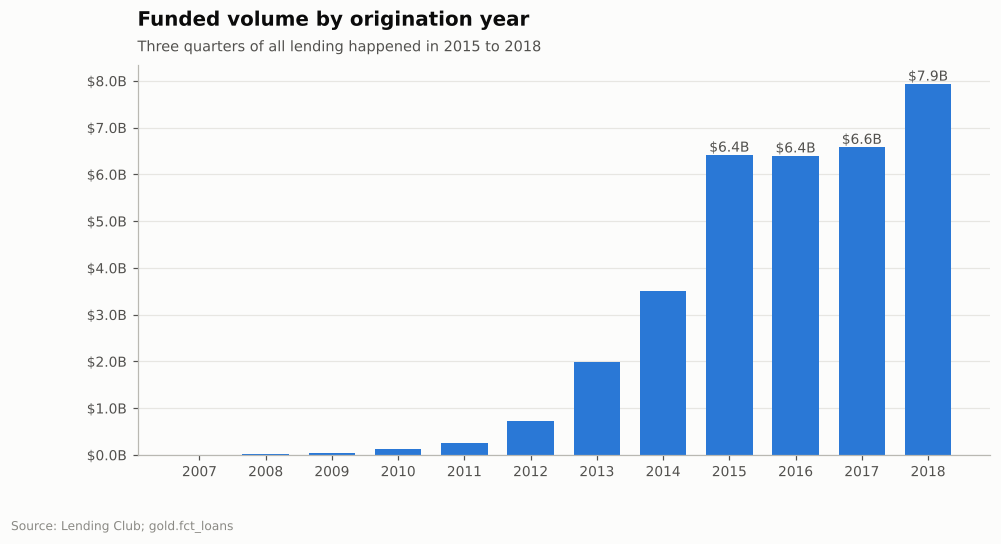

In [6]:
fig, ax = plt.subplots()
ax.bar(q1.issue_year, q1.funded_amount, color=viz.BLUE, width=0.7)
viz.money(ax)
ax.set_title("Funded volume by origination year")
viz.subtitle(ax, "Three quarters of all lending happened in 2015 to 2018")
ax.set_xticks(q1.issue_year)
for x, y in zip(q1.issue_year[-4:], q1.funded_amount[-4:]):
    ax.text(x, y, f"${y / 1e9:.1f}B", ha="center", va="bottom", fontsize=9, color=viz.INK_2)
viz.source(fig, "Lending Club; gold.fct_loans")
plt.show()

**What it means:** the book is **USD 34.0 billion** across 2.26 million loans. Growth was explosive until 2015 (+83% that year) and then flattened. The last four vintages hold 75% of the exposure. Any model must perform well on *recent* borrowers, which is why the split in this project is by time, not random.

### Q2. Is Meridian paid enough for the risk in each grade?

In [7]:
print(load_sql("q02_grade_risk_return"))
q2 = run_sql(con, "q02_grade_risk_return")
q2.style.format({"loans": "{:,.0f}", "share_of_loans": "{:.1%}", "avg_interest_rate": "{:.1%}",
                 "bad_rate_24m": "{:.1%}", "lifetime_default_rate_resolved": "{:.1%}",
                 "realised_loss_rate_resolved": "{:.1%}", "avg_lgd": "{:.1%}"}).hide(axis="index")

-- Q2. Is Meridian paid enough for the risk it takes in each grade?
-- Compares the interest rate charged with the observed 24-month bad rate and
-- realised loss. Skills: conditional aggregation, FILTER, window share.
select
    g.grade,
    count(*)                                                            as loans,
    count(*) / sum(count(*)) over ()                                    as share_of_loans,
    avg(f.interest_rate)                                                as avg_interest_rate,
    avg(f.is_bad_24m::int) filter (where f.has_full_window)             as bad_rate_24m,
    avg(f.is_defaulted::int) filter (where f.is_resolved)               as lifetime_default_rate_resolved,
    sum(f.exposure_at_default - f.net_recoveries) filter (where f.is_resolved)
        / sum(f.funded_amount) filter (where f.is_resolved)             as realised_loss_rate_resolved,
    avg(f.loss_given_default)                                           as avg_lgd
from gold.fct_loans f
join gold.

grade,loans,share_of_loans,avg_interest_rate,bad_rate_24m,lifetime_default_rate_resolved,realised_loss_rate_resolved,avg_lgd
A,"433,027",19.2%,7.1%,2.9%,6.0%,3.2%,91.1%
B,"663,557",29.4%,10.7%,6.5%,13.4%,8.0%,91.0%
C,"650,053",28.8%,14.1%,11.0%,22.4%,14.9%,90.9%
D,"324,424",14.4%,18.1%,16.1%,30.4%,21.4%,90.9%
E,"135,639",6.0%,21.8%,20.6%,38.4%,28.1%,90.6%
F,"41,800",1.8%,25.5%,26.8%,45.1%,34.5%,90.4%
G,"12,168",0.5%,28.1%,31.2%,49.7%,38.5%,90.5%


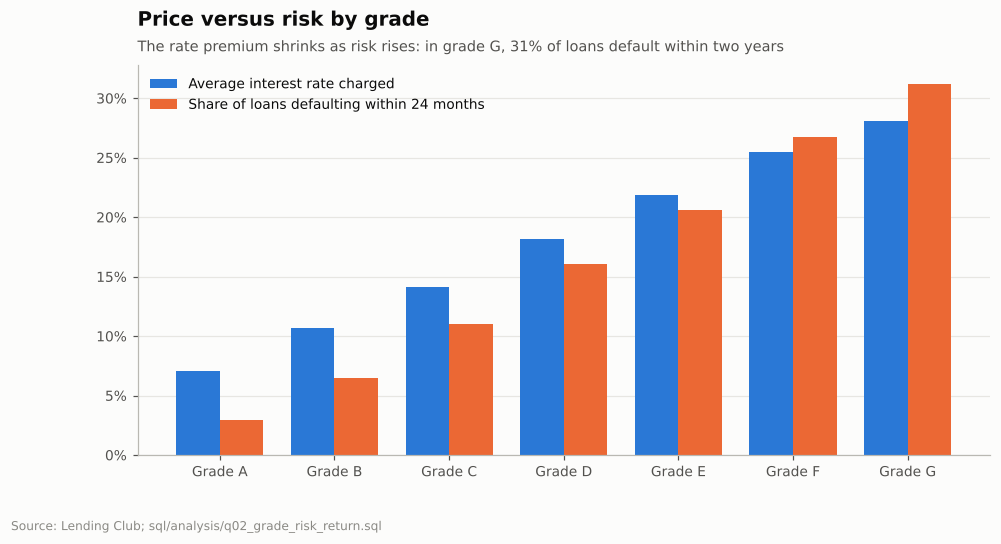

In [8]:
fig, ax = plt.subplots()
x = np.arange(len(q2))
w = 0.38
ax.bar(x - w / 2, q2.avg_interest_rate, w, color=viz.BLUE, label="Average interest rate charged")
ax.bar(x + w / 2, q2.bad_rate_24m, w, color=viz.ORANGE, label="Share of loans defaulting within 24 months")
ax.set_xticks(x, [f"Grade {g}" for g in q2.grade])
viz.pct(ax)
ax.legend(loc="upper left")
ax.set_title("Price versus risk by grade")
viz.subtitle(ax, "The rate premium shrinks as risk rises: in grade G, 31% of loans default within two years")
viz.source(fig, "Lending Club; sql/analysis/q02_grade_risk_return.sql")
plt.show()

**What it means:**

- Risk is well **ranked** by grade: the 24-month bad rate rises monotonically from 2.9% (A) to 31.2% (G).
- Risk is not well **priced** at the bottom. In grade A the rate (7.1%) is more than double the 24-month bad rate. In grades F and G the bad rate is already higher than the rate charged, and those loans keep defaulting after month 24.
- **Loss given default is about 91% in every grade.** Unsecured consumer debt recovers roughly 9 cents on the dollar, so the PD model, not recoveries, is what protects Meridian.

### Q3. Why the naive default rate misleads

In [9]:
print(load_sql("q03_maturity_bias"))
q3 = run_sql(con, "q03_maturity_bias")
q3.style.format({"loans": "{:,.0f}", "naive_default_rate_to_date": "{:.1%}", "bad_rate_24m": "{:.1%}",
                 "share_with_full_window": "{:.0%}"}).hide(axis="index")

-- Q3. Why the naive default rate is misleading for recent vintages.
-- A loan issued in 2018 has had at most 15 months to default. Comparing the
-- naive "defaulted so far" rate with the windowed 24-month rate shows the bias
-- and justifies the target definition and the out-of-time split.
select
    year(issue_month)                                                 as issue_year,
    count(*)                                                          as loans,
    min(months_observed)                                              as min_months_observed,
    avg(is_defaulted::int)                                            as naive_default_rate_to_date,
    avg(is_bad_24m::int) filter (where has_full_window)               as bad_rate_24m,
    avg(has_full_window::int)                                         as share_with_full_window,
    any_value(dataset_split)                                          as dataset_split
from gold.fct_loans
group by 1
order by 1;



issue_year,loans,min_months_observed,naive_default_rate_to_date,bad_rate_24m,share_with_full_window,dataset_split
2007,603,135,26.2%,18.2%,100%,train
2008,"2,393",123,20.7%,14.2%,100%,train
2009,"5,281",111,13.7%,9.0%,100%,train
2010,"12,537",99,14.0%,7.6%,100%,train
2011,"21,721",87,15.2%,8.2%,100%,train
2012,"53,367",75,16.2%,9.2%,100%,train
2013,"134,814",63,15.6%,8.3%,100%,train
2014,"235,629",51,17.5%,9.3%,100%,train
2015,"421,095",39,18.0%,10.7%,100%,validation
2016,"434,407",27,15.7%,11.4%,100%,test_oot


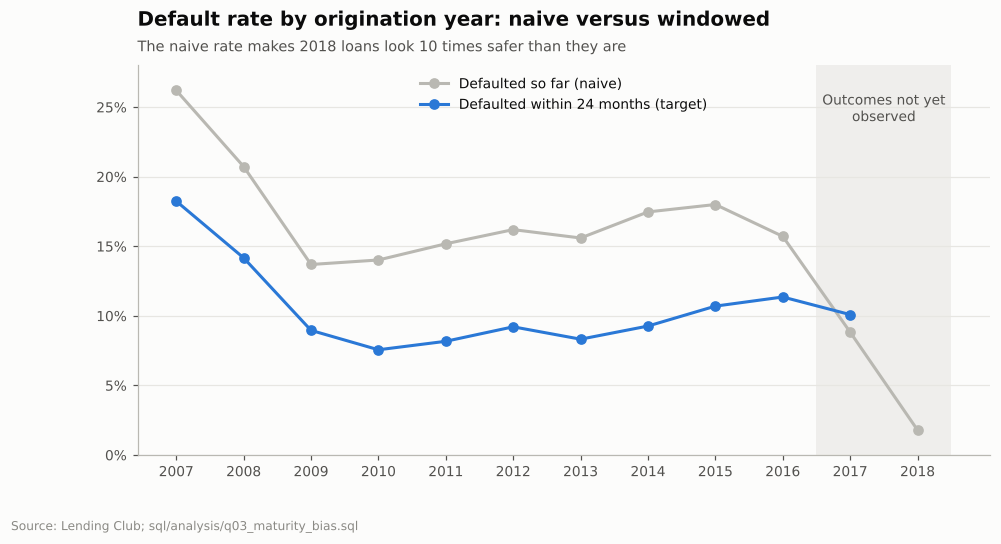

In [10]:
fig, ax = plt.subplots()
ax.plot(q3.issue_year, q3.naive_default_rate_to_date, color=viz.NEUTRAL, marker="o", label="Defaulted so far (naive)")
ax.plot(q3.issue_year, q3.bad_rate_24m, color=viz.BLUE, marker="o", label="Defaulted within 24 months (target)")
ax.axvspan(2016.5, 2018.5, color=viz.GRID, alpha=0.6, lw=0)
ax.text(2017.5, 0.24, "Outcomes not yet\nobserved", ha="center", fontsize=9, color=viz.INK_2)
viz.pct(ax)
ax.set_ylim(0, 0.28)
ax.set_xticks(q3.issue_year)
ax.legend(loc="upper center")
ax.set_title("Default rate by origination year: naive versus windowed")
viz.subtitle(ax, "The naive rate makes 2018 loans look 10 times safer than they are")
viz.source(fig, "Lending Club; sql/analysis/q03_maturity_bias.sql")
plt.show()

**What it means:** a 2018 loan has had at most 15 months to default, so its "1.8% default rate" is an artefact of time, not of quality. Training a model on this would teach it that recent borrowers are safe, exactly the wrong lesson.

**Design decision (applied in `int_loans__outcomes.sql`):**

| Item | Definition |
|---|---|
| Target (`is_bad_24m`) | Loan charged off within 24 months of issue. Charge-off date is estimated as last payment + 5 months, Lending Club's 150-day charge-off rule. |
| Eligible loans | Only loans observed for at least 24 months before the March 2019 snapshot |
| Train | Issued 2007 to 2014 (463,596 loans) |
| Validation | Issued 2015 (421,095 loans): tuning and calibration |
| Test, out of time | Issued 2016 (434,407 loans): touched once, at the end |
| Monitoring | Issued 2017 to 2018: no reliable outcome yet, used to check for population drift |

This mirrors how a bank deploys a model: it is built on the past and judged on a future it has never seen.

### Q4. Vintage curves

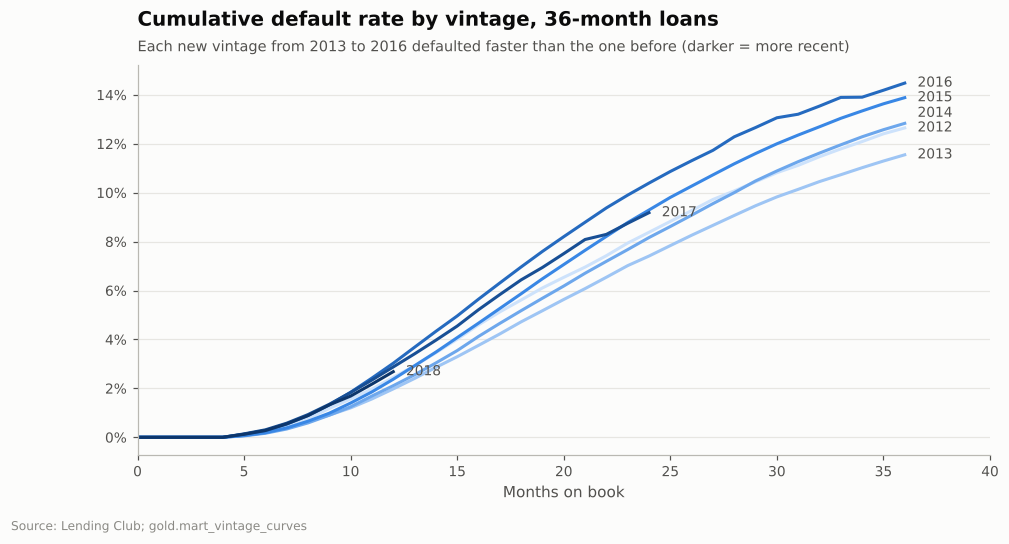

In [11]:
q4 = run_sql(con, "q04_vintage_curves")
fig, ax = plt.subplots()
years = sorted(q4.vintage_year.unique())
ramp = viz.SEQ_BLUE[-len(years):]
ends = []
for color, (yr, g) in zip(ramp, q4.groupby("vintage_year")):
    ax.plot(g.months_on_book, g.cumulative_default_rate, color=color, lw=2)
    last = g.iloc[-1]
    ends.append((last.months_on_book, last.cumulative_default_rate, str(yr)))
viz.label_line_ends(ax, [e for e in ends if e[0] == 36], min_gap=0.006)
viz.label_line_ends(ax, [e for e in ends if e[0] < 36], min_gap=0.006)
viz.pct(ax)
ax.set_xlabel("Months on book")
ax.set_xlim(0, 40)
ax.set_title("Cumulative default rate by vintage, 36-month loans")
viz.subtitle(ax, "Each new vintage from 2013 to 2016 defaulted faster than the one before (darker = more recent)")
viz.source(fig, "Lending Club; gold.mart_vintage_curves")
plt.show()

**What it means:** at 24 months on book, 36-month loans from 2013 had a cumulative default rate of about 7.5%. The same point for 2016 is about 10.4%. Underwriting loosened while the business was growing fast. The 2017 and 2018 curves track 2016 closely, so the deterioration has not reversed. A model trained on 2007 to 2014 must still work on these riskier, more recent borrowers. The out-of-time test is designed to prove it.

### Q5. Geographic concentration

In [12]:
print(load_sql("q05_state_concentration"))
q5 = run_sql(con, "q05_state_concentration")
hhi = q5.portfolio_hhi.iloc[0]
print(f"Portfolio HHI across states: {hhi:,.0f}  (below 1,500 = unconcentrated)")
q5.drop(columns="portfolio_hhi").style.format({"exposure": "${:,.0f}", "share_of_book": "{:.1%}", "bad_rate_24m": "{:.1%}"}).hide(axis="index")

-- Q5. Geographic concentration: top 3 states per census region, plus the
-- Herfindahl-Hirschman Index (HHI) for the whole book.
-- Skills: joins to a dimension, DENSE_RANK, QUALIFY, scalar subquery.
with by_state as (
    select
        d.census_region,
        d.state_name,
        sum(f.funded_amount)                                       as exposure,
        avg(f.is_bad_24m::int) filter (where f.has_full_window)    as bad_rate_24m
    from gold.fct_loans f
    join gold.dim_geography d using (state_code)
    group by all
),
shares as (
    select *, exposure / sum(exposure) over () as share_of_book
    from by_state
)
select
    census_region,
    state_name,
    exposure,
    share_of_book,
    bad_rate_24m,
    dense_rank() over (partition by census_region order by exposure desc)   as rank_in_region,
    (select sum(power(share_of_book * 100, 2)) from shares)                 as portfolio_hhi
from shares
qualify rank_in_region <= 3
order by census_region, rank_in_region;

Portfo

census_region,state_name,exposure,share_of_book,bad_rate_24m,rank_in_region
Midwest,Illinois,"$1,410,059,775",4.1%,8.9%,1
Midwest,Ohio,"$1,076,886,475",3.2%,10.6%,2
Midwest,Michigan,"$841,400,600",2.5%,10.3%,3
Northeast,New York,"$2,766,038,050",8.1%,11.0%,1
Northeast,New Jersey,"$1,315,538,050",3.9%,10.4%,2
Northeast,Pennsylvania,"$1,131,593,850",3.3%,10.3%,3
South,Texas,"$2,930,155,075",8.6%,10.1%,1
South,Florida,"$2,332,060,875",6.9%,11.3%,2
South,Georgia,"$1,136,340,900",3.3%,9.1%,3
West,California,"$4,806,351,950",14.1%,10.8%,1


**What it means:** California (14.1%), Texas (8.6%) and New York (8.1%) are the largest exposures, but the book is **unconcentrated** (HHI 528). Bad rates sit between 8.6% and 11.3% across the largest states, so geography is a weak risk driver compared with the borrower's own credit profile.

### Q6. Does the economy at origination explain credit quality?

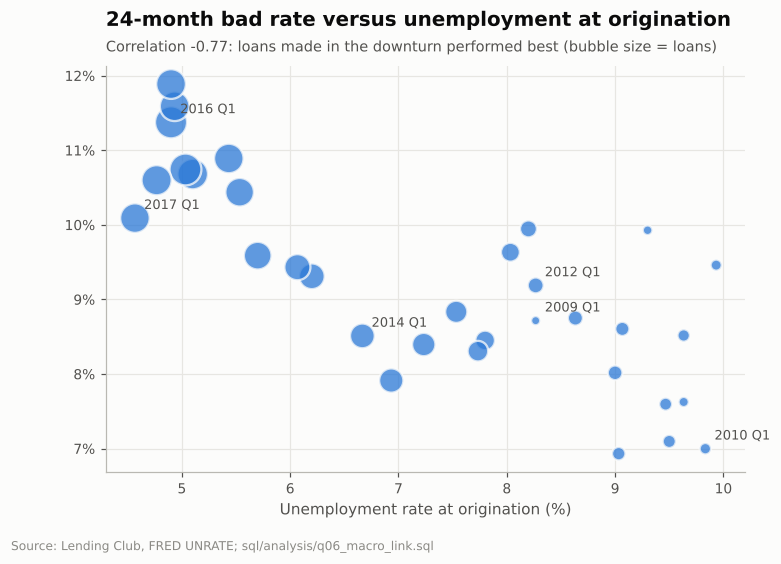

In [13]:
q6 = run_sql(con, "q06_macro_link")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(q6.unemployment_rate, q6.bad_rate_24m, s=np.sqrt(q6.loans) * 1.2, color=viz.BLUE, alpha=0.75,
           edgecolor=viz.SURFACE, linewidth=1.5)
for _, r in q6.iloc[[0, 4, 12, 20, 28, 32]].iterrows():
    ax.annotate(r.quarter.strftime("%Y Q") + str(r.quarter.quarter), (r.unemployment_rate, r.bad_rate_24m),
                xytext=(6, 6), textcoords="offset points", fontsize=8.5, color=viz.INK_2)
viz.pct(ax)
ax.set_xlabel("Unemployment rate at origination (%)")
ax.grid(axis="x", color=viz.GRID)
corr = q6[["bad_rate_24m", "unemployment_rate"]].corr().iloc[0, 1]
ax.set_title("24-month bad rate versus unemployment at origination")
viz.subtitle(ax, f"Correlation {corr:.2f}: loans made in the downturn performed best (bubble size = loans)")
viz.source(fig, "Lending Club, FRED UNRATE; sql/analysis/q06_macro_link.sql")
plt.show()

**What it means:** the relationship runs the opposite way from intuition. Loans made at 9 to 10% unemployment (2009 to 2011) were the *best* performers, because lenders were cautious and the economy improved during those loans' lives. Loans made at 5% unemployment (2015 to 2016) were the *worst*, because standards loosened in good times.

Two consequences for the project:

1. **Economic conditions at origination are not a valid PD feature.** They would capture the lending cycle, not the borrower. The PD model uses only borrower information.
2. **Stress testing must use the economy during a loan's life**, not at its start. Notebook 09 builds this link.

### Q7. How much fraud does the rule engine miss?

In [14]:
q7 = run_sql(con, "q07_fraud_rule_gap")
q7.style.format({"transactions": "{:,.0f}", "fraud_transactions": "{:,.0f}", "fraud_amount": "${:,.0f}",
                 "fraud_rate": "{:.2%}", "rule_alerts": "{:,.0f}", "rule_true_positives": "{:,.0f}",
                 "rule_detection_rate": "{:.2%}", "share_of_fraud_losses": "{:.1%}"}).hide(axis="index")

transaction_type,transactions,fraud_transactions,fraud_amount,fraud_rate,rule_alerts,rule_true_positives,rule_detection_rate,share_of_fraud_losses
transfer,"532,909","4,097","$6,067,213,184",0.77%,16,16,0.39%,50.3%
cash_out,"2,237,500","4,116","$5,989,202,244",0.18%,0,0,0.00%,49.7%


**What it means:** fraud happens only in **transfers and cash-outs**, 8,213 cases worth **USD 12.1 billion** in the simulated month. The current rule engine raised 16 alerts in total and caught **0.2% of fraud cases**. It is precise (every alert was fraud) but almost blind. The fraud model in notebook 10 starts from this gap.

### Q8. Supplier financial health by sector

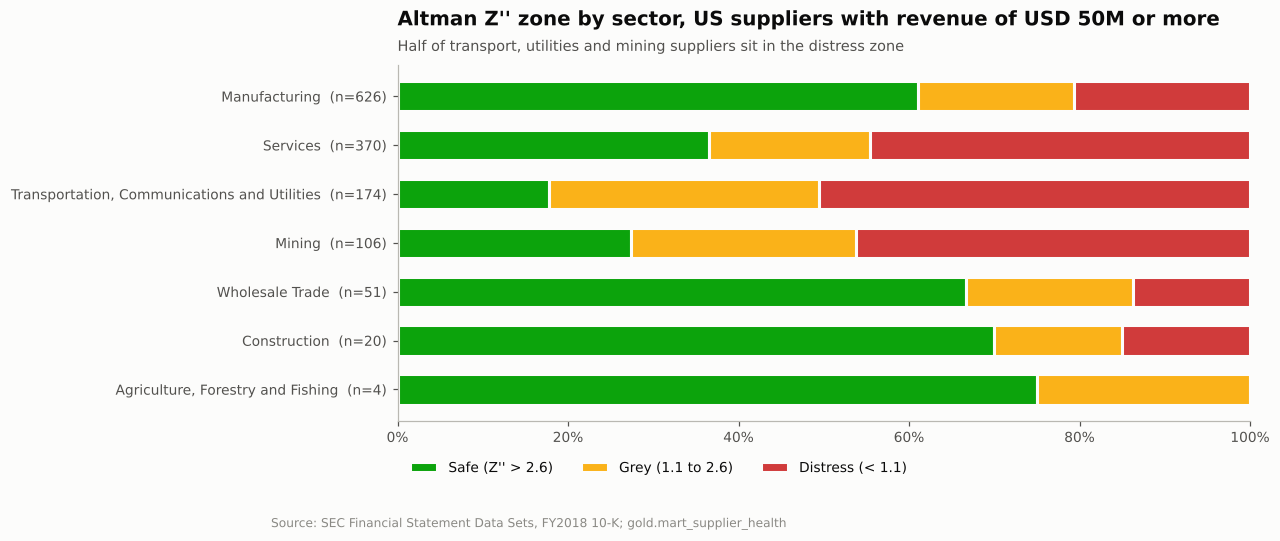

In [15]:
q8 = run_sql(con, "q08_supplier_zones")
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(q8))[::-1]
left = np.zeros(len(q8))
for col, color, label in [("share_safe", viz.GOOD, "Safe (Z'' > 2.6)"),
                          ("share_grey", viz.WARNING, "Grey (1.1 to 2.6)"),
                          ("share_distress", viz.CRITICAL, "Distress (< 1.1)")]:
    ax.barh(y, q8[col], left=left, color=color, height=0.62, label=label, edgecolor=viz.SURFACE, linewidth=2)
    left += q8[col].values
ax.set_yticks(y, [f"{s}  (n={n})" for s, n in zip(q8.sector_name, q8.companies)])
viz.pct(ax, axis="x")
ax.grid(False)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3)
ax.set_title("Altman Z'' zone by sector, US suppliers with revenue of USD 50M or more")
viz.subtitle(ax, "Half of transport, utilities and mining suppliers sit in the distress zone")
viz.source(fig, "SEC Financial Statement Data Sets, FY2018 10-K; gold.mart_supplier_health", y=-0.1)
plt.show()

**What it means:** manufacturing and wholesale suppliers are mostly healthy (61 to 67% in the safe zone). Transport, utilities, mining and services carry far more financial stress. For a procurement team this already suggests where to concentrate monitoring and where Meridian's supplier-finance offer is most relevant (notebook 11).

Note: utilities and telecoms are structurally leveraged, so Altman Z'' is conservative for them. Notebook 11 treats sector context explicitly.

## 5. Summary

| Finding | Consequence for the project |
|---|---|
| 2.26M loans reconciled from source to gold; 33 footer rows and 2,749 policy exceptions explained | The loss figures and the training data tie out |
| Naive default rates are biased by loan age | 24-month target and a strict out-of-time split |
| Vintages deteriorated from 2013 to 2016 | The model must be tested on a later, riskier population |
| LGD is about 91% in every grade | The PD model drives losses; recoveries barely help |
| Unemployment at origination correlates negatively with defaults | Macro data is used for stress testing, not as a PD feature |
| Rule engine catches 0.2% of fraud | Large, measurable room for a fraud model |
| Supplier stress is concentrated in four sectors | Sector-aware supplier monitoring |

**Next:** notebook 02 audits the data column by column before any of it reaches a model.